In [ ]:
# cell: setup
# Shared scaffolding, generated from client.py by scripts/sync_client.py: edit client.py, not this block.
# Everything defined here (the API helpers and their imports) is visible to every cell.
import hashlib
import mimetypes
import os
import time
from pathlib import Path

import requests


_session = requests.Session()
_session.headers["User-Agent"] = "atlas-engine-notebooks"


def _call(method, path, **kw):
    # Env is read per call, so a key exported after import still takes effect.
    base = os.environ.get("MOTH_API_BASE", "https://api.mothquantum.com").rstrip("/")
    key = os.environ.get("MOTH_API_KEY", "")
    if not key:
        raise RuntimeError("MOTH_API_KEY is not set: create a key on the Atlas API keys page and export it")
    r = _session.request(method, f"{base}/api/v1{path}", headers={"Authorization": f"Bearer {key}"}, timeout=30, **kw)
    if r.status_code >= 400:  # keep the API's error body; raise_for_status() would drop it
        raise RuntimeError(f"{method} {path} -> {r.status_code}: {r.text[:300]}")
    return r.json() if r.content else None


def _presigned(method, url, **kw):
    # Presigned URLs carry their own signature: never send the API key to them (plain requests, not _session).
    r = requests.request(method, url, timeout=60, **kw)
    if r.status_code >= 400:
        raise RuntimeError(f"{method} presigned URL -> {r.status_code}: {r.text[:300]}")
    return r


_uploaded = {}  # (sha256, content_type) -> asset_id, so re-running a cell doesn't re-upload


def upload(file: str | os.PathLike | bytes, content_type: str | None = None, filename: str | None = None) -> str:
    """Upload a file path or raw bytes; returns its asset id.

    content_type defaults to a guess from the filename; filename names uploaded bytes.
    Runs the three API steps: create, PUT to the presigned URL, complete."""
    if isinstance(file, (bytes, bytearray)):
        data, filename = bytes(file), filename or "file"
    else:
        data, filename = Path(file).read_bytes(), filename or Path(file).name
    content_type = content_type or mimetypes.guess_type(filename)[0] or "application/octet-stream"
    key = (hashlib.sha256(data).hexdigest(), content_type)
    if key not in _uploaded:
        asset = _call("POST", "/assets", json={"filename": filename, "content_type": content_type, "size_bytes": len(data)})
        up = asset["upload"]
        _presigned(up.get("method", "PUT"), up["url"], data=data, headers=up["headers"])
        _uploaded[key] = _call("POST", f"/assets/{asset['asset_id']}/complete")["asset_id"]
    return _uploaded[key]


def submit(engine: str, params: dict, input_files: dict[str, str] | None = None) -> str:
    """Start a job on an engine; returns its job id. params is a dict of the engine's parameters; input_files is a dict mapping each input slot name to an asset id."""
    body = {"params": params, **({"input_files": input_files} if input_files else {})}
    return _call("POST", f"/engines/{engine}/process", json=body)["job_id"]


def wait(job_id: str, interval: float = 1.5, timeout: float = 600, on_update=None) -> None:
    """Block until the job completes, checking every interval seconds; raises if it fails, is cancelled, or takes longer than timeout seconds.

    on_update(job) is called whenever the status changes, with the status response as a dict,
    e.g. on_update=lambda job: print(job["status"])."""
    deadline, last = time.monotonic() + timeout, None
    while time.monotonic() < deadline:
        job = _call("GET", f"/jobs/{job_id}/status")
        if on_update and job["status"] != last:
            on_update(job)
            last = job["status"]
        if job["status"] == "completed":
            return
        if job["status"] in ("failed", "cancelled"):
            raise RuntimeError(f"Job {job_id} {job['status']}: {job.get('error')}")
        time.sleep(interval)
    raise TimeoutError(f"Job {job_id} did not finish in {timeout}s")


def download(job_id: str, slot: str = "result") -> bytes | dict:
    """Return a finished job's output: the bytes of the file in slot (or the first output), or the inline JSON result (a dict) for engines that produce no file."""
    res = _call("GET", f"/jobs/{job_id}/result")
    outputs = res.get("outputs") or []
    out = next((o for o in outputs if o.get("slot") == slot), outputs[0] if outputs else None)
    if out is None:
        if res.get("result") is None:
            raise RuntimeError(f"Job {job_id} finished without an output")
        return res["result"]
    url = out.get("url") or _call("GET", f"/assets/{out['output_asset_id']}/download")["download_url"]
    return _presigned("GET", url).content

# Headless exports: run every cell without pressing buttons. (Own line: marimo drops a trailing comment on save.)
AUTORUN = os.environ.get("MOTH_AUTORUN") == "1"

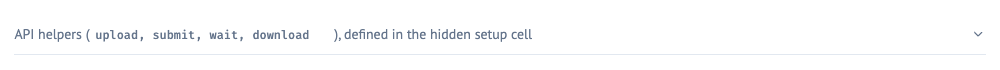

In [ ]:
# cell: helpers
# Generated by scripts/sync_client.py. Lists the API helpers from their own signatures and docstrings.
import inspect as _inspect

_summary = lambda f: _inspect.getdoc(f).partition("\n\n")[0]  # docstring's first paragraph
_docs = "\n".join(f"{f.__name__}{_inspect.signature(f)}\n    {_summary(f)}" for f in (upload, submit, wait, download))
_helpers = mo.accordion({"API helpers (`upload, submit, wait, download`), defined in the hidden setup cell": mo.plain_text(_docs)})
_missing_key = mo.callout(mo.md(
    "`MOTH_API_KEY` is not set, so the cells that call the engine will fail. "
    "Create a key on the Atlas **API keys** page, export it, and restart the kernel."), kind="warn")
mo.vstack([_missing_key, _helpers]) if not os.environ.get("MOTH_API_KEY") else _helpers

In [ ]:
# cell: imports
# Blur's own imports. The hidden setup cell already provides the API helpers and the modules they use
# (os, time, requests, ...), so those are not imported again here.
import io
import math

import marimo as mo
import numpy as np
from PIL import Image

In [ ]:
# cell: display helpers
# Convert between images and float arrays, and lay out labelled image grids.
def as_float(img):
    return np.asarray(img.convert("RGB"), float) / 255.0

def png(arr):
    """Float array in [0, 1] (RGB or gray) -> PNG bytes."""
    buf = io.BytesIO()
    Image.fromarray((np.clip(arr, 0, 1) * 255).astype(np.uint8)).save(buf, "PNG")
    return buf.getvalue()

def panel(label, arr, width=220):
    return mo.vstack([mo.image(src=png(arr), width=width), mo.md(f"<small>{label}</small>")], align="center", gap=0)

def row(panels, **kw):
    return mo.hstack([panel(k, v, **kw) for k, v in panels.items()], justify="start", gap=1, wrap=True)

# Blur

Quantum Blur turns an image into a single quantum state, rotates every qubit once, and measures the state back into pixels. One gate moves amplitude between pixels that can be far apart, so instead of soft focus you get echoes and interference that no convolution kernel produces.

This notebook calls the `blur-v1` engine through the Moth API: **Try it** runs it with your parameters, **How it works** explains the circuit, **Experiments** sweeps one parameter at a time, and **Reference** lists exactly what goes in and comes out.

## Load an image

Drop your own image below, or leave it empty to use the sample cat that ships with this notebook.

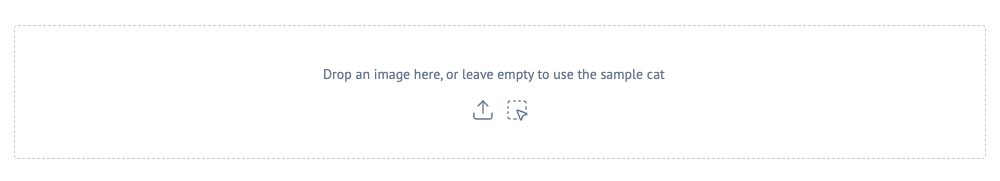

In [ ]:
# cell: image-input
image_upload = mo.ui.file(filetypes=["image/*"], kind="area", label="Drop an image here, or leave empty to use the sample cat")
image_upload

In [ ]:
# cell: default image
# Uses the uploaded file if there is one, otherwise the sample next to this notebook (fetched from GitHub if missing).
SAMPLE = "cat.png"
SAMPLE_URL = f"https://raw.githubusercontent.com/moth-quantum/atlas-engine-notebooks/main/blur/{SAMPLE}"

def load_sample():
    path = mo.notebook_dir() / SAMPLE
    return path.read_bytes() if path.exists() else requests.get(SAMPLE_URL, timeout=60).content

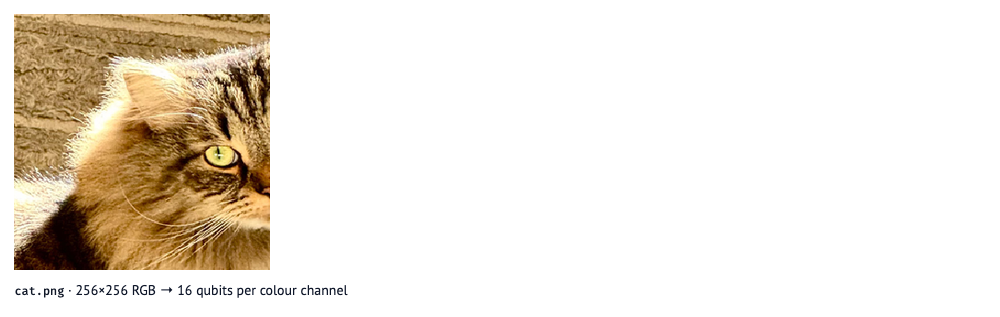

In [ ]:
# cell: load and preview
image_name = image_upload.name() or SAMPLE
image_bytes = image_upload.contents() or load_sample()
image = Image.open(io.BytesIO(image_bytes))
image_px = as_float(image)  # float RGB in [0, 1], what the engine's output is compared against
width, height = image.size

qubits = math.ceil(math.log2(width)) + math.ceil(math.log2(height))
mo.vstack([mo.image(image_bytes, width=256),
           mo.md(f"`{image_name}` · {width}×{height} {image.mode} → {qubits} qubits per colour channel")])

## Call the engine

Every engine is called with the same four helpers: `upload` the inputs, `submit` a job, `wait` for it, `download` the output. What is specific to Blur is the engine id, its input slots (`image`, optional `mask`) and decoding the output image.

In [ ]:
# cell: blur
ENGINE_ID = "blur-v1"

def blur(params, image, filename, mask=None):
    """Run one Blur job on image (bytes named filename). Returns (float RGB array in [0, 1], seconds)."""
    input_files = {"image": upload(image, filename=filename)}
    if mask is not None:
        input_files["mask"] = upload(mask, filename="mask.png")
    t0 = time.perf_counter()
    job_id = submit(ENGINE_ID, params, input_files)
    with mo.status.spinner(title=f"Blur job {job_id}") as spinner:
        wait(job_id, on_update=lambda job: spinner.update(subtitle=job["status"]))
    data = download(job_id)
    return as_float(Image.open(io.BytesIO(data))), time.perf_counter() - t0

## Try it

The engine's parameters, all optional. Change a control, then press **Run Blur** to submit one job.

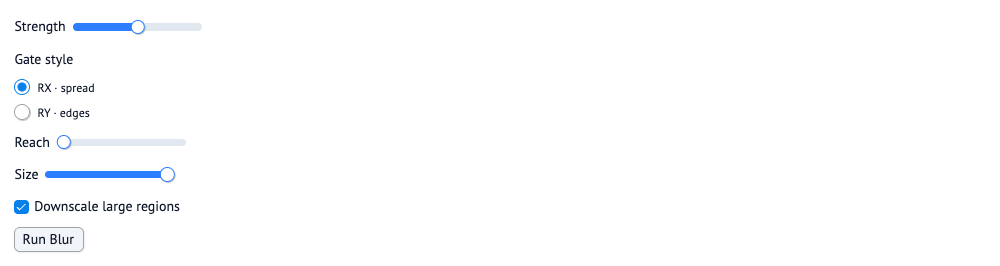

In [ ]:
# cell: params
strength = mo.ui.slider(0, 1, step=0.05, value=0.5, label="Strength")  # 0..1 rotation scale; 0 = identity
style = mo.ui.radio(options={"RX · spread": "rx", "RY · edges": "ry"}, value="RX · spread", label="Gate style")
reach = mo.ui.slider(0, 1, step=0.05, value=0.0, label="Reach")  # 0 = local angles, 1 = every qubit turns equally
size = mo.ui.slider(8, 1024, step=8, value=1024, label="Size")  # pixel budget per pass -> 2*ceil(log2 size) qubits
downscale = mo.ui.checkbox(value=True, label="Downscale large regions")  # over budget: shrink (on) or tile (off)
run = mo.ui.run_button(label="Run Blur")
mo.vstack([strength, style, reach, size, downscale, run])

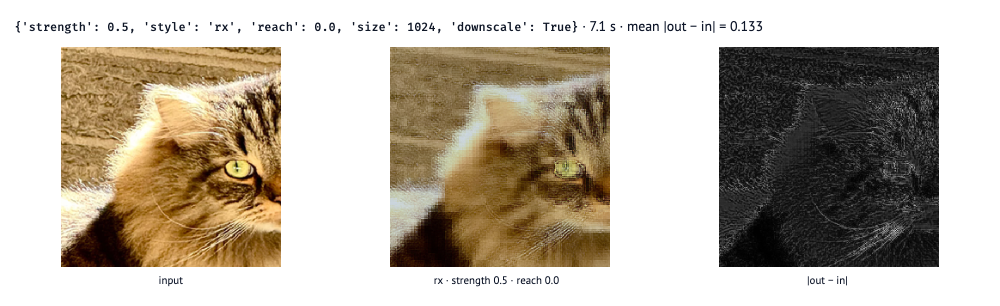

In [ ]:
# cell: run
mo.stop(not (run.value or AUTORUN), mo.md("Press **Run Blur** to submit a job with the parameters above."))
PARAMS = {"strength": strength.value, "style": style.value, "reach": reach.value, "size": size.value, "downscale": downscale.value}
a_out, t = blur(PARAMS, image_bytes, image_name)
diff = np.abs(a_out - image_px)
mo.vstack([
    mo.md(f"`{PARAMS}` · {t:.1f} s · mean |out − in| = {diff.mean():.3f}"),
    row({"input": image_px, f"{PARAMS['style']} · strength {PARAMS['strength']} · reach {PARAMS['reach']}": a_out,
         "|out − in|": diff.mean(-1) / max(diff.max(), 1e-6)}),
])

## How it works

Quantum Blur has no convolution kernel. The image is encoded as a single quantum state, each qubit is rotated once, and the state is measured back into pixels. Because a single gate redistributes amplitude between pixels that may be far apart on the canvas, the output shows interference patterns rather than soft focus.

**Encode.** Pixel $(x,y)$ with brightness $h$ maps to a basis state, Gray-coded per axis:

$$|\psi\rangle \;\propto\; \sum_{x,y} \sqrt{h(x,y)}\;|g(x)\,g(y)\rangle, \qquad n = \lceil\log_2 W\rceil + \lceil\log_2 H\rceil \text{ qubits}$$

**Rotate.** One `rx` (or `ry`) per qubit, with an image-dependent angle:

$$\theta_q = \pi\,\xi\,\big[(1-\text{reach})\, r_q + \text{reach}\big], \qquad \xi = \text{strength} \;(\texttt{rx})\;\text{ or }\;\text{strength}^2 \;(\texttt{ry})$$

where $r_q$ is the normalised brightness on neighbour pairs whose labels differ in qubit $q$.

**Read back.** $h' = |\text{amp}|^2 / \max$, rescaled to the channel's original maximum. With a mask $m$, the output is $m\cdot\text{blurred} + (1-m)\cdot\text{original}$.

## Experiments

Each experiment sweeps one parameter with the others fixed, so you can see what it does on its own. Each has its own run button, and nothing is submitted until you press it.

### Strength

$\xi$ scales every angle. At 0 the round trip is exact; the echoes grow with it up to the schema's limit of 1 (past that the rotations would start to undo themselves, which is why the engine stops there).

In [ ]:
# cell: strength-params
# Edit these, then press the run button: one job per value in the sweep.
STRENGTH_SWEEP = (0.0, 0.25, 0.5, 0.75, 1.0)
STRENGTH_FIXED = {"style": "rx", "reach": 0.0}

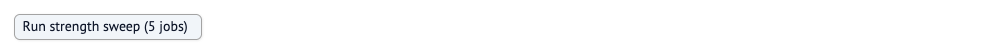

In [ ]:
# cell: strength-run
run_strength = mo.ui.run_button(label=f"Run strength sweep ({len(STRENGTH_SWEEP)} jobs)")
run_strength

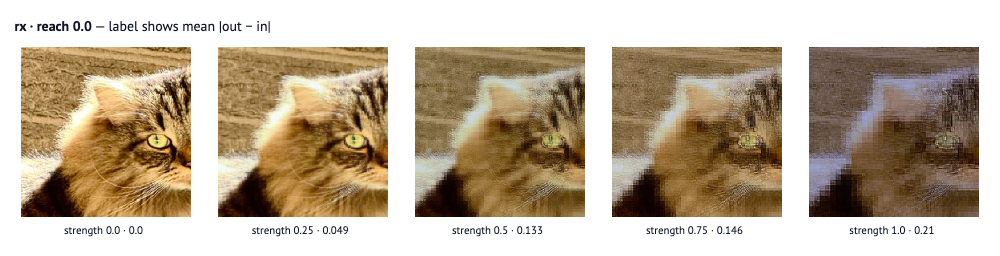

In [ ]:
# cell: strength
mo.stop(not (run_strength.value or AUTORUN), mo.md(f"Press **Run strength sweep** to run this cell ({len(STRENGTH_SWEEP)} jobs)."))
outs = {k: blur({**STRENGTH_FIXED, "strength": k}, image_bytes, image_name)[0] for k in STRENGTH_SWEEP}
diffs = {k: round(float(np.abs(o - image_px).mean()), 3) for k, o in outs.items()}
mo.vstack([
    mo.md(f"**{STRENGTH_FIXED['style']} · reach {STRENGTH_FIXED['reach']}** — label shows mean |out − in|"),
    row({f"strength {k} · {diffs[k]}": o for k, o in outs.items()}, width=170),
])

### Reach and style

`reach` lifts the locality: at 0 the angle on each qubit is weighted by the brightness it separates, at 1 every qubit turns by the same $\pi\xi$ and echoes land anywhere on the canvas. `ry` keeps the same angles (with $\xi = \text{strength}^2$) but its interference terms cancel instead of spreading, so weight collects at a few pixels and smooth areas go dark.

In [ ]:
# cell: reach-params
# Edit these, then press the run button: one job per style × reach.
REACH_SWEEP = (0.0, 0.5, 1.0)
REACH_STYLES = ("rx", "ry")
REACH_FIXED = {"strength": 0.5}

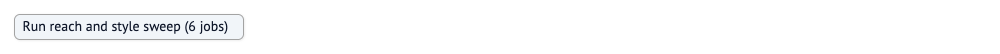

In [ ]:
# cell: reach-run
run_reach = mo.ui.run_button(label=f"Run reach and style sweep ({len(REACH_STYLES) * len(REACH_SWEEP)} jobs)")
run_reach

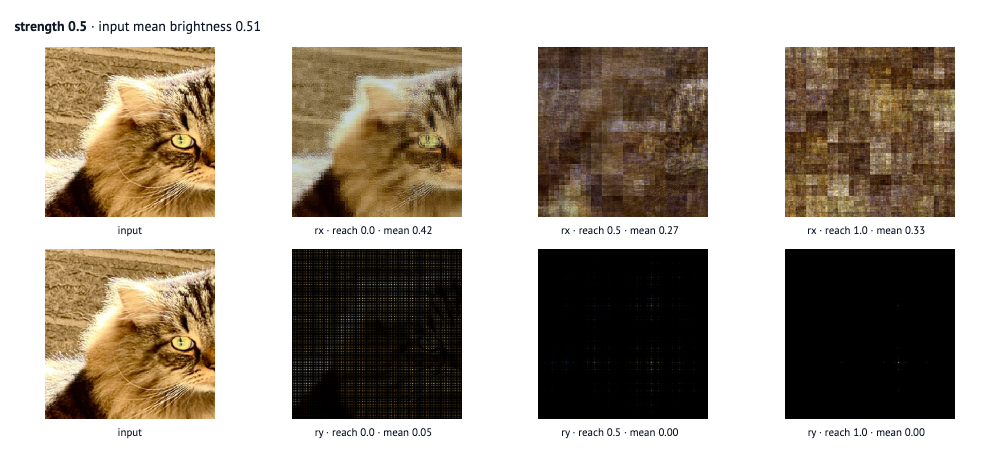

In [ ]:
# cell: reach
mo.stop(not (run_reach.value or AUTORUN), mo.md(f"Press **Run reach and style sweep** to run this cell ({len(REACH_STYLES) * len(REACH_SWEEP)} jobs)."))
rows = []
for st in REACH_STYLES:
    panels = {"input": image_px}
    for r in REACH_SWEEP:
        o = blur({**REACH_FIXED, "style": st, "reach": r}, image_bytes, image_name)[0]
        panels[f"{st} · reach {r} · mean {o.mean():.2f}"] = o
    rows.append(row(panels, width=170))
mo.vstack([mo.md(f"**strength {REACH_FIXED['strength']}** · input mean brightness {image_px.mean():.2f}"), *rows])

### Mask

A feathered disc: 1 inside, a soft ramp, 0 outside. The engine blurs the disc's bounding box as its own state and blends by mask intensity, so pixels outside the mask must come back untouched and the edge must be a gradient, not a seam.

In [ ]:
# cell: mask-params
# Edit these, then press the run button (one job).
MASK_PARAMS = {"style": "rx", "reach": 0.0, "strength": 0.8}
MASK_RADIUS = 0.28  # disc scale, as a fraction of the image's shorter side
MASK_RAMP = 1.6  # mask = clip(MASK_RAMP - distance / radius, 0, 1): 1 inside, a soft edge, 0 outside

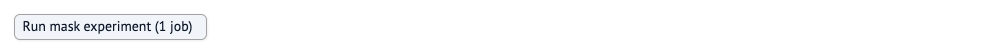

In [ ]:
# cell: mask-run
run_mask = mo.ui.run_button(label="Run mask experiment (1 job)")
run_mask

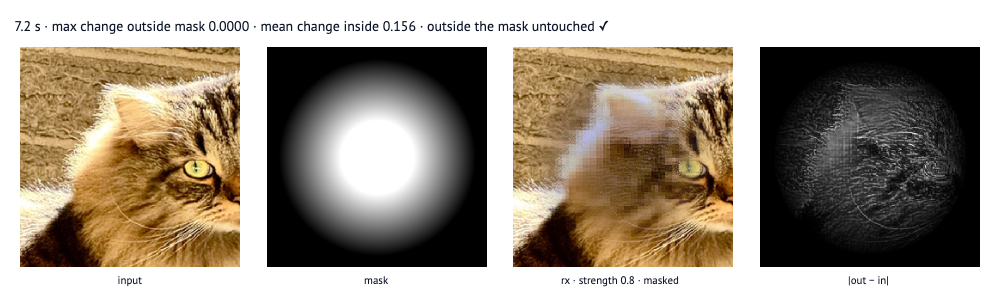

In [ ]:
# cell: mask
mo.stop(not (run_mask.value or AUTORUN), mo.md("Press **Run mask experiment** to run this cell (1 job)."))
yy, xx = np.mgrid[0:height, 0:width]
soft = np.clip(MASK_RAMP - np.hypot(xx - width / 2, yy - height / 2) / (MASK_RADIUS * min(width, height)), 0, 1)
a_m, t_mask = blur(MASK_PARAMS, image_bytes, image_name, mask=png(soft))
d = np.abs(a_m - image_px).mean(-1)
outside = d[soft == 0].max()
verdict = "outside the mask untouched ✓" if outside < 1 / 255 else "**outside the mask changed — the blend contract is broken**"
mo.vstack([
    mo.md(f"{t_mask:.1f} s · max change outside mask {outside:.4f} · mean change inside {d[soft == 1].mean():.3f} · {verdict}"),
    row({
        "input": image_px,
        "mask": soft,
        f"{MASK_PARAMS['style']} · strength {MASK_PARAMS['strength']} · masked": a_m,
        "|out − in|": d / max(d.max(), 1e-6),
    }),
])

## Reference

### What you send, what comes back

| you send | the engine does |
|---|---|
| `image` (PNG / JPEG / WebP / TIFF / BMP, any mode) | one statevector per RGB channel per region; alpha passed through; same format and size back |
| `mask`, or none | connected regions of the mask (after a small-noise bin and min-region filter); else the alpha channel; else the whole canvas |
| `strength`, `style`, `reach` | the per-qubit angles above |
| `size`, `downscale` | the qubit budget: a region over budget is downscaled or tiled per region, never the whole image |

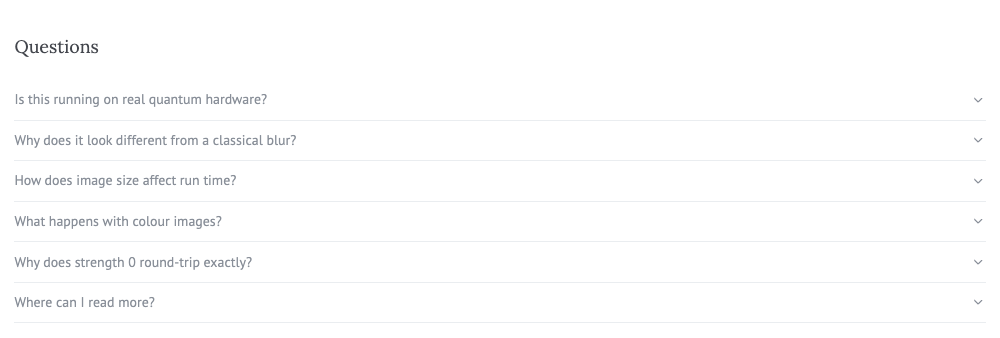

In [ ]:
# cell: questions
mo.vstack([mo.md("### Questions"), mo.accordion({
    "Is this running on real quantum hardware?":
        "No. Blur runs on a classical statevector simulator, so jobs run on CPU or GPU. The circuits and the interference are real; the execution is emulated. That keeps results exact and repeatable with no shot noise. Real hardware would need very high connectivity and enough shots to rebuild the whole state, which is not yet practical at image scale.",
    "Why does it look different from a classical blur?":
        "A classical blur averages each pixel with a fixed neighbourhood. Blur has no kernel: one rotation per qubit mixes amplitude between every pixel at once, so the shape of the smear comes from the circuit, not a window. That is where the echo-like, non-local look comes from.",
    "How does image size affect run time?":
        "Qubits grow with the log of the image size (16 for 256 × 256, 20 for 1024 × 1024), but simulator memory and time grow exponentially with qubits. Regions over the qubit budget are downscaled or tiled, depending on `downscale`.",
    "What happens with colour images?":
        "Each of red, green and blue is blurred as its own state and the channels are recombined. The same technique was used on ILĀ's [Recurse album](https://infinite.mothquantum.com).",
    "Why does strength 0 round-trip exactly?":
        "Encoding normalises the state, which throws away absolute brightness. The engine keeps each channel's original maximum and restores it on read-back, so with no rotation the output equals the input.",
    "Where can I read more?":
        "The open-source [QuantumBlur repository](https://github.com/qiskit-community/QuantumBlur) walks through the underlying library.",
})])